# 15 · Ablation Study

**The question:** Which parts of the proposed model actually matter? An **ablation study** removes one part at a time, keeps everything else
exactly the same, and measures the change. A part that can be removed without loss is not a contribution.

| | |
|---|---|
| **Input** | The proposed model from Notebook 14 |
| **What we do** | Train one variant per removed part (3 seeds each), compare each with the full model seed by seed, and build the final results table |
| **Output** | The ablation table, the complete results table for the paper, and the **final detector** used in Notebooks 16-19 |

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.notebook_helpers import (TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json,
                                  read_json, setup_style, write_leaderboard)
from src.flow_networks import FlowData, run_config, paired_comparison, bootstrap_difference, leaderboard_row, score, DEVICE
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

PROPOSED = read_json(MODELS / '14_proposed_config.json')['config']
PROPOSED.pop('feature_set', None)
print('proposed:', {k: PROPOSED[k] for k in ['weighting', 'scales', 'fusion', 'tcn_bilstm', 'channels', 'lr']}, '| device:', DEVICE)
data = FlowData('total_and_byte44')
data42 = FlowData('original42')

proposed: {'weighting': 'sqrt', 'scales': [3, 5, 7], 'fusion': 'cross', 'tcn_bilstm': True, 'channels': 64, 'lr': 0.001} | device: cuda


## 2. The variants

Each variant changes **one** thing. A part that is not in the proposed model is tested by **adding** it instead, so every design choice is checked.

In [2]:
variants = {'Full proposed model': (PROPOSED, data)}
variants['without rare-class weighting' if PROPOSED['weighting'] != 'none' else 'with balanced weighting'] = (
    dict(PROPOSED, weighting='none' if PROPOSED['weighting'] != 'none' else 'balanced'), data)
variants['single-scale convolution' if PROPOSED['scales'] != [3] else 'with multi-scale convolution'] = (
    dict(PROPOSED, scales=[3] if PROPOSED['scales'] != [3] else [3, 5, 7]), data)
variants['self-attention instead of cross' if PROPOSED['fusion'] == 'cross' else 'cross-attention instead of self'] = (
    dict(PROPOSED, fusion='self' if PROPOSED['fusion'] == 'cross' else 'cross'), data)
variants['no attention at all'] = (dict(PROPOSED, fusion='none'), data)
variants['without TCN-BiLSTM' if PROPOSED['tcn_bilstm'] else 'with TCN-BiLSTM'] = (dict(PROPOSED, tcn_bilstm=not PROPOSED['tcn_bilstm']), data)
variants['without engineered features (original42)'] = (PROPOSED, data42)
display(pd.DataFrame([{'variant': k, 'weighting': c['weighting'], 'scales': c['scales'], 'fusion': c['fusion'], 'TCN-BiLSTM': c['tcn_bilstm'],
                       'features': d.feature_set} for k, (c, d) in variants.items()]))

,variant,weighting,scales,fusion,TCN-BiLSTM,features
0,Full proposed model,sqrt,"[3, 5, 7]",cross,True,total_and_byte44
1,without rare-class weighting,none,"[3, 5, 7]",cross,True,total_and_byte44
2,single-scale convolution,sqrt,[3],cross,True,total_and_byte44
3,self-attention instead of cross,sqrt,"[3, 5, 7]",self,True,total_and_byte44
4,no attention at all,sqrt,"[3, 5, 7]",none,True,total_and_byte44
5,without TCN-BiLSTM,sqrt,"[3, 5, 7]",cross,False,total_and_byte44
6,without engineered features (original42),sqrt,"[3, 5, 7]",cross,True,original42


## 3. Train every variant (3 seeds each)

Variants already trained in Notebooks 10-14 are loaded from their saved checkpoints (same settings, same seeds), not retrained.

In [3]:
results, probs = {}, {}
for name, (config, d) in variants.items():
    runs, proba, _, _ = run_config(d, config, label=name)
    results[name], probs[name] = runs, proba

Full proposed model seed 42: model_selection macro F1 0.6135 | stopping macro F1 0.6074


Full proposed model seed 43: model_selection macro F1 0.5917 | stopping macro F1 0.5950


Full proposed model seed 44: model_selection macro F1 0.6023 | stopping macro F1 0.6113


without rare-class weighting seed 42: model_selection macro F1 0.5523 | stopping macro F1 0.5356


without rare-class weighting seed 43: model_selection macro F1 0.5375 | stopping macro F1 0.5574


without rare-class weighting seed 44: model_selection macro F1 0.5204 | stopping macro F1 0.5235


... (11 outputs left out)

without TCN-BiLSTM seed 44: model_selection macro F1 0.5831 | stopping macro F1 0.5812


without engineered features (original42) seed 42: model_selection macro F1 0.6019 | stopping macro F1 0.5946


without engineered features (original42) seed 43: model_selection macro F1 0.5844 | stopping macro F1 0.5925


without engineered features (original42) seed 44: model_selection macro F1 0.6132 | stopping macro F1 0.6015


## 4. The ablation table

,macro F1 mean,macro F1 std,false-positive rate,Worms correct (mean of 13),change vs full,seeds worse than full,verdict over seeds
variant,,,,,,,
Full proposed model,0.6025,0.0109,0.1560,7.6667,NaN,NaN,NaN
without rare-class weighting,0.5367,0.0160,0.0950,1.0000,-0.0658,3.0000,second clearly better
single-scale convolution,0.6045,0.0094,0.1523,8.0000,0.0019,1.0000,could be chance
self-attention instead of cross,0.5985,0.0052,0.1678,8.0000,-0.0040,1.0000,depends on the seed
no attention at all,0.5939,0.0095,0.1716,7.0000,-0.0086,2.0000,depends on the seed
without TCN-BiLSTM,0.5955,0.0113,0.1736,8.0000,-0.0071,2.0000,depends on the seed
without engineered features (original42),0.5999,0.0145,0.1714,8.3333,-0.0026,2.0000,depends on the seed


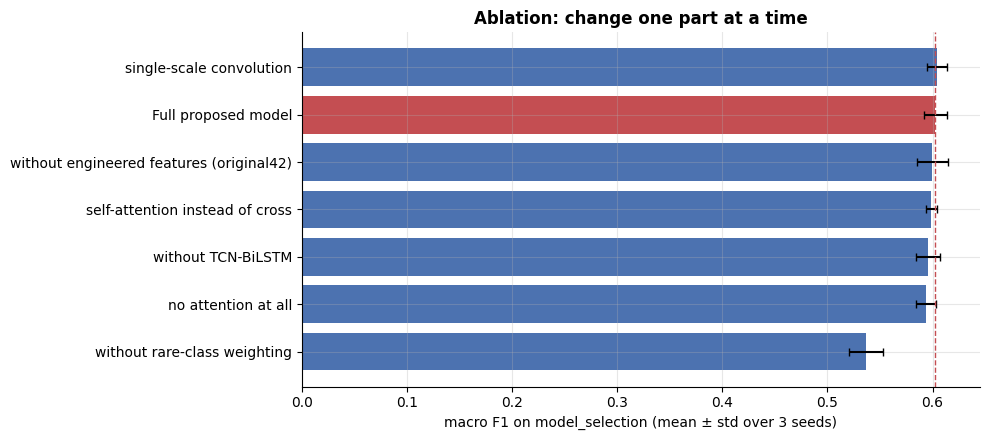

In [4]:
y_eval = data.y['model_selection'].numpy()
full = probs['Full proposed model']
ablation = []
for name, runs in results.items():
    row = {'variant': name, 'macro F1 mean': runs['macro F1'].mean(), 'macro F1 std': runs['macro F1'].std(),
           'false-positive rate': runs['false-positive rate'].mean(), 'Worms correct (mean of 13)': runs['Worms correct (of 13)'].mean()}
    if name != 'Full proposed model':
        frame, overall = paired_comparison(y_eval, probs[name], full, f'{name} vs full')
        row.update({'change vs full': row['macro F1 mean'] - results['Full proposed model']['macro F1'].mean(),
                    'seeds worse than full': int((frame.difference < 0).sum()), 'verdict over seeds': overall})
    ablation.append(row)
ablation = pd.DataFrame(ablation).set_index('variant')
save_table(ablation, '15_ablation', index=True)
display(ablation)

fig, ax = plt.subplots(figsize=(10, 4.5))
shown = ablation.sort_values('macro F1 mean')
colors = ['#C44E52' if v == 'Full proposed model' else '#4C72B0' for v in shown.index]
ax.barh(range(len(shown)), shown['macro F1 mean'], xerr=shown['macro F1 std'], color=colors, capsize=3)
ax.set_yticks(range(len(shown)), shown.index)
ax.axvline(ablation.loc['Full proposed model', 'macro F1 mean'], color='#C44E52', ls='--', lw=1)
ax.set(xlabel='macro F1 on model_selection (mean ± std over 3 seeds)', title='Ablation: change one part at a time')
plt.tight_layout(); save_figure(fig, '15_ablation'); plt.show()

**What we see:**

- **Only one part is clearly essential: the rare-class weighting.** Without it the model drops from 0.603 to **0.537** (-0.066), clearly worse for
  every seed, and finds 1 Worms row instead of about 8 (although with fewer false alarms: 9.5% vs 15.6%).
- **The architecture blocks each matter very little inside the final design:**
  - single-scale instead of multi-scale: +0.002 (the multi-scale block is not needed here);
  - self-attention instead of cross-attention: -0.004; no attention at all: -0.009;
  - without TCN-BiLSTM: -0.007; without the two engineered features: -0.003.
  Every one of these "depends on the seed": no block is clearly better or worse for all three seeds.
- Cross-attention and TCN-BiLSTM do consistently **lower the false-alarm rate** (removing either raises it from 15.6% to about 17%).

This is an important, honest result: the gain of the proposed network over the earlier networks (Notebook 14) comes **mainly from the sqrt class
weighting**, not from its architecture blocks. The blocks offer small, seed-dependent improvements.

## 5. A simple combination: LightGBM + proposed network

The tree model and the network make different mistakes (Notebooks 08 and 14). A **fixed 50/50 average of their probabilities** needs no tuning,
so it does not use `model_selection` to pick anything. We test it as one more candidate.

In [5]:
d10 = read_json(MODELS / '10_rare_class_choice.json')
lgbm_name = 'LightGBM' if d10['lightgbm_treatment'] == 'none' else f"LightGBM ({d10['lightgbm_treatment']})"
lgbm_proba = pd.read_csv(DATA / f"10_lightgbm_{d10['lightgbm_treatment']}_proba.csv").to_numpy()
blend = {seed: (lgbm_proba + p) / 2 for seed, p in full.items()}
blend_runs = pd.DataFrame([{'seed': s, **score(y_eval, p)} for s, p in blend.items()])
lgbm_score = score(y_eval, lgbm_proba)
blend_tests = []
for seed, p in blend.items():
    d, lo, hi, v = bootstrap_difference(y_eval, p.argmax(1), lgbm_proba.argmax(1))
    blend_tests.append({'comparison': f'50/50 blend vs {lgbm_name}', 'seed': seed, 'difference': d, '95% low': lo, '95% high': hi, 'verdict': v})
blend_tests = pd.DataFrame(blend_tests)
save_table(blend_tests, '15_blend_significance')
display(pd.DataFrame({lgbm_name: lgbm_score, 'blend (mean of 3 seeds)': blend_runs.drop(columns='seed').mean()}).T)
display(blend_tests)

,macro F1,accuracy,attack recall,false-positive rate,attack avg precision,Worms correct (of 13)
LightGBM (sqrt),0.6662,0.8176,0.9883,0.1202,0.9966,11.0000
blend (mean of 3 seeds),0.6443,0.8098,0.9912,0.1395,0.9965,9.6667


,comparison,seed,difference,95% low,95% high,verdict
0,50/50 blend vs LightGBM (sqrt),42,-0.0189,-0.0359,-0.0058,second clearly better
1,50/50 blend vs LightGBM (sqrt),43,-0.0224,-0.0369,-0.0094,second clearly better
2,50/50 blend vs LightGBM (sqrt),44,-0.0244,-0.0421,-0.0097,second clearly better


## 6. The final results table (for the paper)

One row per model, all on the same 17,534 `model_selection` rows. Models with seeds show mean ± std.

In [6]:
paper_rows = [
    ('Logistic regression', 'leaderboard_06.csv', 'Logistic regression', 'total_and_byte44'),
    ('Decision tree (3 seeds)', 'leaderboard_06.csv', 'Decision tree', 'total_and_byte44'),
    ('LightGBM', 'leaderboard_06.csv', 'LightGBM', 'total_and_byte44'),
    ('MLP (3 seeds)', 'leaderboard_07.csv', 'MLP (128/64)', 'total_and_byte44'),
    ('Reference Conv1D + attention, CPU (3 seeds)', 'leaderboard_08.csv', 'Conv1D + attention (A)', 'total_and_byte44'),
]
from src.notebook_helpers import TABLES
final = []
for label, file, model, fs in paper_rows:
    board = pd.read_csv(TABLES / file)
    r = board[(board.model == model) & (board['feature set'] == fs)].iloc[0]
    final.append({'model': label, 'macro F1': r['macro F1 mean'], 'std': r['macro F1 std'], 'accuracy': r['accuracy'],
                  'attack recall': r['attack recall'], 'false-positive rate': r['false-positive rate'], 'Worms (of 13)': r['Worms correct (of 13)']})
if lgbm_name != 'LightGBM':
    final.append({'model': lgbm_name, 'macro F1': lgbm_score['macro F1'], 'std': np.nan, 'accuracy': lgbm_score['accuracy'],
                  'attack recall': lgbm_score['attack recall'], 'false-positive rate': lgbm_score['false-positive rate'],
                  'Worms (of 13)': lgbm_score['Worms correct (of 13)']})
for label, runs in [('Proposed model (3 seeds)', results['Full proposed model']), ('Blend: LightGBM + proposed (3 seeds)', blend_runs)]:
    final.append({'model': label, 'macro F1': runs['macro F1'].mean(), 'std': runs['macro F1'].std(), 'accuracy': runs['accuracy'].mean(),
                  'attack recall': runs['attack recall'].mean(), 'false-positive rate': runs['false-positive rate'].mean(),
                  'Worms (of 13)': runs['Worms correct (of 13)'].mean()})
final = pd.DataFrame(final).sort_values('macro F1', ascending=False).reset_index(drop=True)
save_table(final, '15_paper_results_table')
display(final.round(4))

,model,macro F1,std,accuracy,attack recall,false-positive rate,Worms (of 13)
0,LightGBM (sqrt),0.6662,NaN,0.8176,0.9883,0.1202,11.0000
1,Blend: LightGBM + proposed (3 seeds),0.6443,0.0028,0.8098,0.9912,0.1395,9.6667
2,LightGBM,0.6320,NaN,0.8356,0.9753,0.0845,9.0000
3,Decision tree (3 seeds),0.6107,0.0058,0.8139,0.9624,0.0843,7.0000
4,Proposed model (3 seeds),0.6025,0.0109,0.7972,0.9911,0.1560,7.6667
5,"Reference Conv1D + attention, CPU (3 seeds)",0.5349,0.0121,0.8206,0.9688,0.0961,0.6667
6,MLP (3 seeds),0.5241,0.0107,0.8133,0.9756,0.1168,0.0000
7,Logistic regression,0.4242,NaN,0.7768,0.9718,0.1364,0.0000


**What we see:**

- **LightGBM with sqrt weights is the best model (0.666)**, ahead of the blend (0.644), plain LightGBM (0.632), the decision tree (0.611) and the proposed
  network (0.603). Logistic regression is far behind (0.424).
- **The 50/50 blend does not help:** it is clearly below LightGBM (sqrt) for every seed. Averaging in the weaker network dilutes LightGBM's
  strength on the rare classes.
- Among the neural networks, the proposed model is clearly the best (0.603 vs 0.535 and 0.524).
- Every model catches 96-99% of attacks; they differ in attack *types* and in false alarms (8-16%).

## 7. The final detector

**Rule (fixed in advance):** the candidate with the highest macro F1 on `model_selection` among LightGBM (with its Notebook 10 treatment),
the proposed model and the blend. If two are within 0.001, the simpler one wins (LightGBM, then the proposed model, then the blend).
This detector is explained (16), calibrated (17), used for reports (18) and tested once (19).

Its score here is slightly optimistic, because `model_selection` has now been used to compare many candidates. The official test file will show
the real performance.

In [7]:
candidates = pd.DataFrame([
    {'detector': 'lightgbm', 'name': lgbm_name, 'macro F1': lgbm_score['macro F1'], 'simplicity': 0},
    {'detector': 'proposed', 'name': 'Proposed model', 'macro F1': results['Full proposed model']['macro F1'].mean(), 'simplicity': 1},
    {'detector': 'blend', 'name': 'Blend: LightGBM + proposed', 'macro F1': blend_runs['macro F1'].mean(), 'simplicity': 2},
])
top = candidates['macro F1'].max()
chosen = candidates[candidates['macro F1'] >= top - 0.001].sort_values('simplicity').iloc[0]
final_detector = {'detector': chosen.detector, 'name': chosen['name'], 'model_selection macro F1': round(float(chosen['macro F1']), 4),
                  'lightgbm_treatment': d10['lightgbm_treatment'], 'lightgbm_model': f"models/v3/10_lightgbm_{d10['lightgbm_treatment']}.joblib",
                  'network_config': PROPOSED, 'network_seeds': [42, 43, 44],
                  'note': 'blend = mean of LightGBM and the 3-seed average of the proposed network' if chosen.detector == 'blend' else ''}
save_json(final_detector, MODELS / 'final_detector.json')
display(candidates)
display(pd.Series(final_detector).to_frame('final detector'))
write_leaderboard('15', [leaderboard_row(f'Ablation: {k}', r, feature_set=variants[k][1].feature_set) for k, r in results.items() if k != 'Full proposed model']
                  + [leaderboard_row('Blend: LightGBM + proposed', blend_runs.assign(parameters=np.nan, **{'train minutes': np.nan}))])
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

,detector,name,macro F1,simplicity
0,lightgbm,LightGBM (sqrt),0.6662,0
1,proposed,Proposed model,0.6025,1
2,blend,Blend: LightGBM + proposed,0.6443,2


,final detector
detector,lightgbm
name,LightGBM (sqrt)
model_selection macro F1,0.6662
lightgbm_treatment,sqrt
lightgbm_model,models/v3/10_lightgbm_sqrt.joblib
network_config,"{'scales': [3, 5, 7], 'fusion': 'cross', 'tcn_..."
network_seeds,"[42, 43, 44]"
note,


## Summary

### What we learned

| Question | Answer |
|---|---|
| Which part of the proposed model matters most? | **The sqrt rare-class weighting** (-0.066 without it, clear for every seed) |
| Do the architecture blocks matter? | Only slightly: each changes macro F1 by 0.009 or less, and the direction depends on the seed |
| Does a LightGBM + network blend help? | **No**: 0.644, clearly below LightGBM (sqrt) for every seed |
| Best model on `model_selection` | **LightGBM with sqrt weights: macro F1 0.666** |
| Final detector (fixed rule) | **LightGBM (sqrt)** → explained (16), calibrated (17), used for reports (18), tested once (19) |

### What this means for the paper

Two findings are stronger than "a new architecture wins":

1. **Class weighting is the single most effective change** for both tree and neural models on UNSW-NB15 (LightGBM +0.034, network +0.07), and it beats
   SMOTE, the reference paper's choice.
2. **Architecture complexity adds little on single-flow data:** multi-scale convolution, cross-attention and TCN-BiLSTM give small, seed-dependent changes,
   and a weighted tree ensemble remains clearly better and far cheaper.

### What is still uncertain

- All of this is on `model_selection`, which has now been used to compare many candidates, so the 0.666 is somewhat optimistic. Notebook 19 measures
  the real performance on the official test file.

### What comes next

**Notebook 16** explains the final detector's decisions with SHAP and LIME, and tests whether those explanations are faithful.